In [62]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression
 

In [63]:
# inputDir = Path['..']
# outDir = Path['..']
RANDOM_STATE = 24
np.random.seed(RANDOM_STATE)

rng = np.random.default_rng(seed = RANDOM_STATE)

NOISE = 0.2
EPOCHES = 200
ALPHA = 0.1
N_SAMPLES = 50

In [64]:
inpDir = Path(r'E:\Backup Files Abhinav_Satyam\Deep Neural Network\Datasets\DNN INPUT\input')
RANDOM_STATE = 24

In [65]:
data_df = pd.read_csv(inpDir / 'breast_cancer_mod.csv')
data_df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,0,0,0,0,0,0,0,0,0,1,...,0,0,0,1,1,0,0,1,1,0
1,0,1,0,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
2,0,1,0,0,0,0,0,0,0,1,...,1,0,1,0,1,1,0,1,1,0
3,0,1,0,0,0,0,0,0,0,1,...,1,0,0,0,0,0,0,1,1,0
4,0,0,0,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,1,0


In [66]:
data_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   mean radius              569 non-null    int64
 1   mean texture             569 non-null    int64
 2   mean perimeter           569 non-null    int64
 3   mean area                569 non-null    int64
 4   mean smoothness          569 non-null    int64
 5   mean compactness         569 non-null    int64
 6   mean concavity           569 non-null    int64
 7   mean concave points      569 non-null    int64
 8   mean symmetry            569 non-null    int64
 9   mean fractal dimension   569 non-null    int64
 10  radius error             569 non-null    int64
 11  texture error            569 non-null    int64
 12  perimeter error          569 non-null    int64
 13  area error               569 non-null    int64
 14  smoothness error         569 non-null    int64
 15  compac

In [67]:
data_df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

Text(0.5, 1.0, 'Distribution Of Target Columns')

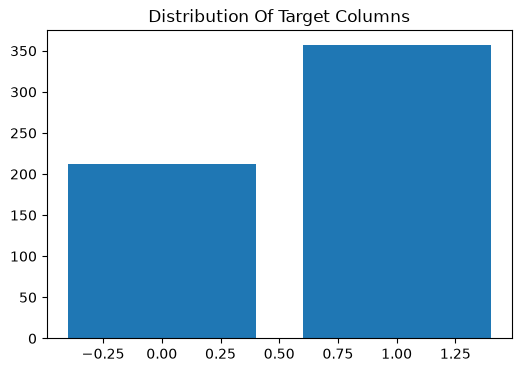

In [68]:
class_names = ['Malignant','Benign']

fig, ax = plt.subplots(figsize = (6,4))
ax.bar(data_df['target'].value_counts().index , 
       data_df['target'].value_counts().values)
ax.set_title('Distribution Of Target Columns')

In [69]:
features = data_df.drop('target' , axis=1)
labels = data_df['target']

X_train , X_test , y_train, y_test = train_test_split(features , labels , test_size=0.25, stratify=labels , random_state=RANDOM_STATE)

In [70]:
print(X_train.shape , X_test.shape, y_train.shape, y_test.shape)

(426, 30) (143, 30) (426,) (143,)


In [71]:
### Training

In [72]:
X_train["total"] = X_train.astype(np.int16).sum(axis=1)
X_train["target"] = y_train

X_train.sort_values("total", inplace= True)
X_train.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,total,target
0,0,0,0,0,0,0,0,0,0,1,...,0,0,1,1,0,0,1,1,12,0
1,0,1,0,1,0,0,0,0,0,0,...,0,1,0,0,0,0,0,1,13,0
2,0,1,0,0,0,0,0,0,0,1,...,0,1,0,1,1,0,1,1,13,0
6,0,0,0,0,1,0,0,0,1,1,...,0,0,0,0,0,0,1,1,15,0
5,0,0,0,0,0,0,0,0,0,1,...,0,1,0,1,0,0,1,1,15,0


In [73]:

accuracy = {}

for b in range(X_train.shape[1]):
    X_train['y_pred'] = X_train['total'] >=b
    accuracy[b] = accuracy_score(y_true = X_train['target'],
                                y_pred=X_train['y_pred'])    

In [74]:
accuracy

{0: 0.6267605633802817,
 1: 0.6267605633802817,
 2: 0.6267605633802817,
 3: 0.6267605633802817,
 4: 0.6267605633802817,
 5: 0.6267605633802817,
 6: 0.6267605633802817,
 7: 0.6267605633802817,
 8: 0.6267605633802817,
 9: 0.6267605633802817,
 10: 0.6267605633802817,
 11: 0.6267605633802817,
 12: 0.6267605633802817,
 13: 0.6291079812206573,
 14: 0.6338028169014085,
 15: 0.6338028169014085,
 16: 0.6408450704225352,
 17: 0.647887323943662,
 18: 0.6572769953051644,
 19: 0.6619718309859155,
 20: 0.6713615023474179,
 21: 0.6901408450704225,
 22: 0.7089201877934272,
 23: 0.7323943661971831,
 24: 0.7699530516431925,
 25: 0.8051643192488263,
 26: 0.8286384976525821,
 27: 0.8474178403755869,
 28: 0.8450704225352113,
 29: 0.8192488262910798,
 30: 0.7394366197183099,
 31: 0.3732394366197183}